# Oracle VirtualBox Network Adapter Benchmark Analysis
**Research Project:** Comparative Evaluation of NAT, Host-Only, and Bridged Networking Modes on Virtual Machine Performance  
**Subject:** Virtualisasi dan Komputasi Awan (Kelas 2023F)  
**Host Environment:** AMD Ryzen 9 5900HX (8C/16T @ 3.30GHz, boost up to 4.27GHz), 16 GB DDR4, Intel Wi-Fi 6 AX200 (160MHz), Windows 11  
**Guest Environment:** Ubuntu Server 24.04 LTS (2 vCPU, 4096 MB RAM, Intel PRO/1000 MT Desktop adapter)  
**Methodology:** 30 controlled benchmark iterations per mode (90 total iterations) using `iperf3` (throughput) and `ping` (ICMP RTT latency).


In [2]:
# centralized configuration
from pathlib import Path

CONFIG = {
    "data_dir": Path("benchmark_data"),
    "output_figures_dir": Path("figures"),
    "output_results_dir": Path("results"),
    "expected_runs": 30,
    "modes": {
        "NAT": {"iperf": "nat_iperf.txt", "ping": "nat_ping.txt", "color": "#e74c3c"},
        "Host-Only": {"iperf": "hostonly_iperf.txt", "ping": "hostonly_ping.txt", "color": "#2ecc71"},
        "Bridged": {"iperf": "bridged_iperf.txt", "ping": "bridged_ping.txt", "color": "#3498db"}
    },
    "regex": {
        "iperf": r"([\d\.]+)\s+([GM]bits/sec)",
        "ping": r"=\s*([\d\.]+)/([\d\.]+)/([\d\.]+)/([\d\.]+)\s*ms"
    },
    "figures": {
        "dpi": 300,
        "format": "png"
    }
}

# ensure output directories exist upfront
CONFIG["output_figures_dir"].mkdir(parents=True, exist_ok=True)
CONFIG["output_results_dir"].mkdir(parents=True, exist_ok=True)


In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# setup global styling with clean grid
plt.style.use("tableau-colorblind10" if "tableau-colorblind10" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "DejaVu Sans", "Arial"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#e5e5e5"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.alpha"] = 0.7


In [4]:
def extract_throughput_mbps(line: str, pattern: str) -> float:
    match = re.search(pattern, line)
    if not match:
        raise ValueError(f"failed to parse iperf throughput from line: '{line.strip()}'")
    val, unit = float(match.group(1)), match.group(2)
    # normalize gbits to mbits for uniform scale
    return val * 1000.0 if "Gbits" in unit else val

def extract_ping_latencies(line: str, pattern: str) -> dict:
    match = re.search(pattern, line)
    if not match:
        raise ValueError(f"failed to parse ping rtt from line: '{line.strip()}'")
    min_lat, avg_lat, max_lat, mdev_lat = [float(x) for x in match.groups()]
    return {
        "latency_min_ms": min_lat,
        "latency_avg_ms": avg_lat,
        "latency_max_ms": max_lat,
        "jitter_mdev_ms": mdev_lat
    }

def load_and_validate_dataset(config: dict) -> pd.DataFrame:
    data_dir = config["data_dir"]
    if not data_dir.is_dir():
        raise FileNotFoundError(f"data directory '{data_dir}' does not exist")
        
    records = []
    expected_runs = config["expected_runs"]
    
    for mode, meta in config["modes"].items():
        iperf_file = data_dir / meta["iperf"]
        ping_file = data_dir / meta["ping"]
        
        # fail fast if files are missing
        if not iperf_file.exists():
            raise FileNotFoundError(f"missing iperf log for {mode}: {iperf_file}")
        if not ping_file.exists():
            raise FileNotFoundError(f"missing ping log for {mode}: {ping_file}")
            
        iperf_lines = [ln.strip() for ln in iperf_file.read_text(encoding="utf-8").splitlines() if ln.strip()]
        ping_lines = [ln.strip() for ln in ping_file.read_text(encoding="utf-8").splitlines() if ln.strip()]
        
        # assert completeness
        if len(iperf_lines) != expected_runs:
            raise ValueError(f"{mode} iperf has {len(iperf_lines)} lines, expected {expected_runs}")
        if len(ping_lines) != expected_runs:
            raise ValueError(f"{mode} ping has {len(ping_lines)} lines, expected {expected_runs}")
            
        for run_id, (i_ln, p_ln) in enumerate(zip(iperf_lines, ping_lines), 1):
            tp = extract_throughput_mbps(i_ln, config["regex"]["iperf"])
            latencies = extract_ping_latencies(p_ln, config["regex"]["ping"])
            records.append({
                "run": run_id,
                "mode": mode,
                "throughput_mbps": tp,
                **latencies
            })
            
    df = pd.DataFrame(records)
    print(f"dataset successfully loaded: {len(df)} total rows across {len(config['modes'])} modes")
    return df

df = load_and_validate_dataset(CONFIG)
df.head(6)


dataset successfully loaded: 90 total rows across 3 modes


,run,mode,throughput_mbps,latency_min_ms,latency_avg_ms,latency_max_ms,jitter_mdev_ms
0,1,NAT,393.0,0.591,1.014,1.679,0.369
1,2,NAT,722.0,0.686,0.950,1.513,0.289
2,3,NAT,570.0,0.633,0.805,0.967,0.113
3,4,NAT,559.0,0.763,0.857,1.034,0.098
4,5,NAT,496.0,0.720,0.835,0.911,0.077
5,6,NAT,491.0,0.687,0.817,0.976,0.109


In [5]:
def compute_summary_table(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    summary = df.groupby("mode", sort=False)[metric].agg([
        ("Mean", "mean"),
        ("Std Dev", "std"),
        ("Median", "median"),
        ("Min", "min"),
        ("Max", "max"),
        ("p95", lambda x: np.percentile(x, 95))
    ]).round(3)
    return summary

tp_summary = compute_summary_table(df, "throughput_mbps")
lat_summary = compute_summary_table(df, "latency_avg_ms")

print("=== THROUGHPUT SUMMARY (Mbits/sec) ===")
print(tp_summary.to_string())

print("")
print("=== LATENCY (AVG RTT) SUMMARY (ms) ===")
print(lat_summary.to_string())

# save to csv
tp_summary.to_csv(CONFIG["output_results_dir"] / "summary_throughput.csv")
lat_summary.to_csv(CONFIG["output_results_dir"] / "summary_latency.csv")


=== THROUGHPUT SUMMARY (Mbits/sec) ===
              Mean  Std Dev  Median    Min    Max     p95
mode                                                     
NAT        544.600   74.547   554.5  364.0  727.0  668.45
Host-Only  519.033  101.069   508.0  359.0  959.0  573.20
Bridged    678.900   68.099   694.5  573.0  847.0  755.55

=== LATENCY (AVG RTT) SUMMARY (ms) ===
            Mean  Std Dev  Median    Min    Max    p95
mode                                                  
NAT        0.865    0.095   0.848  0.740  1.160  1.026
Host-Only  0.602    0.092   0.572  0.483  0.861  0.786
Bridged    0.603    0.112   0.575  0.465  1.011  0.764


### Throughput Comparison

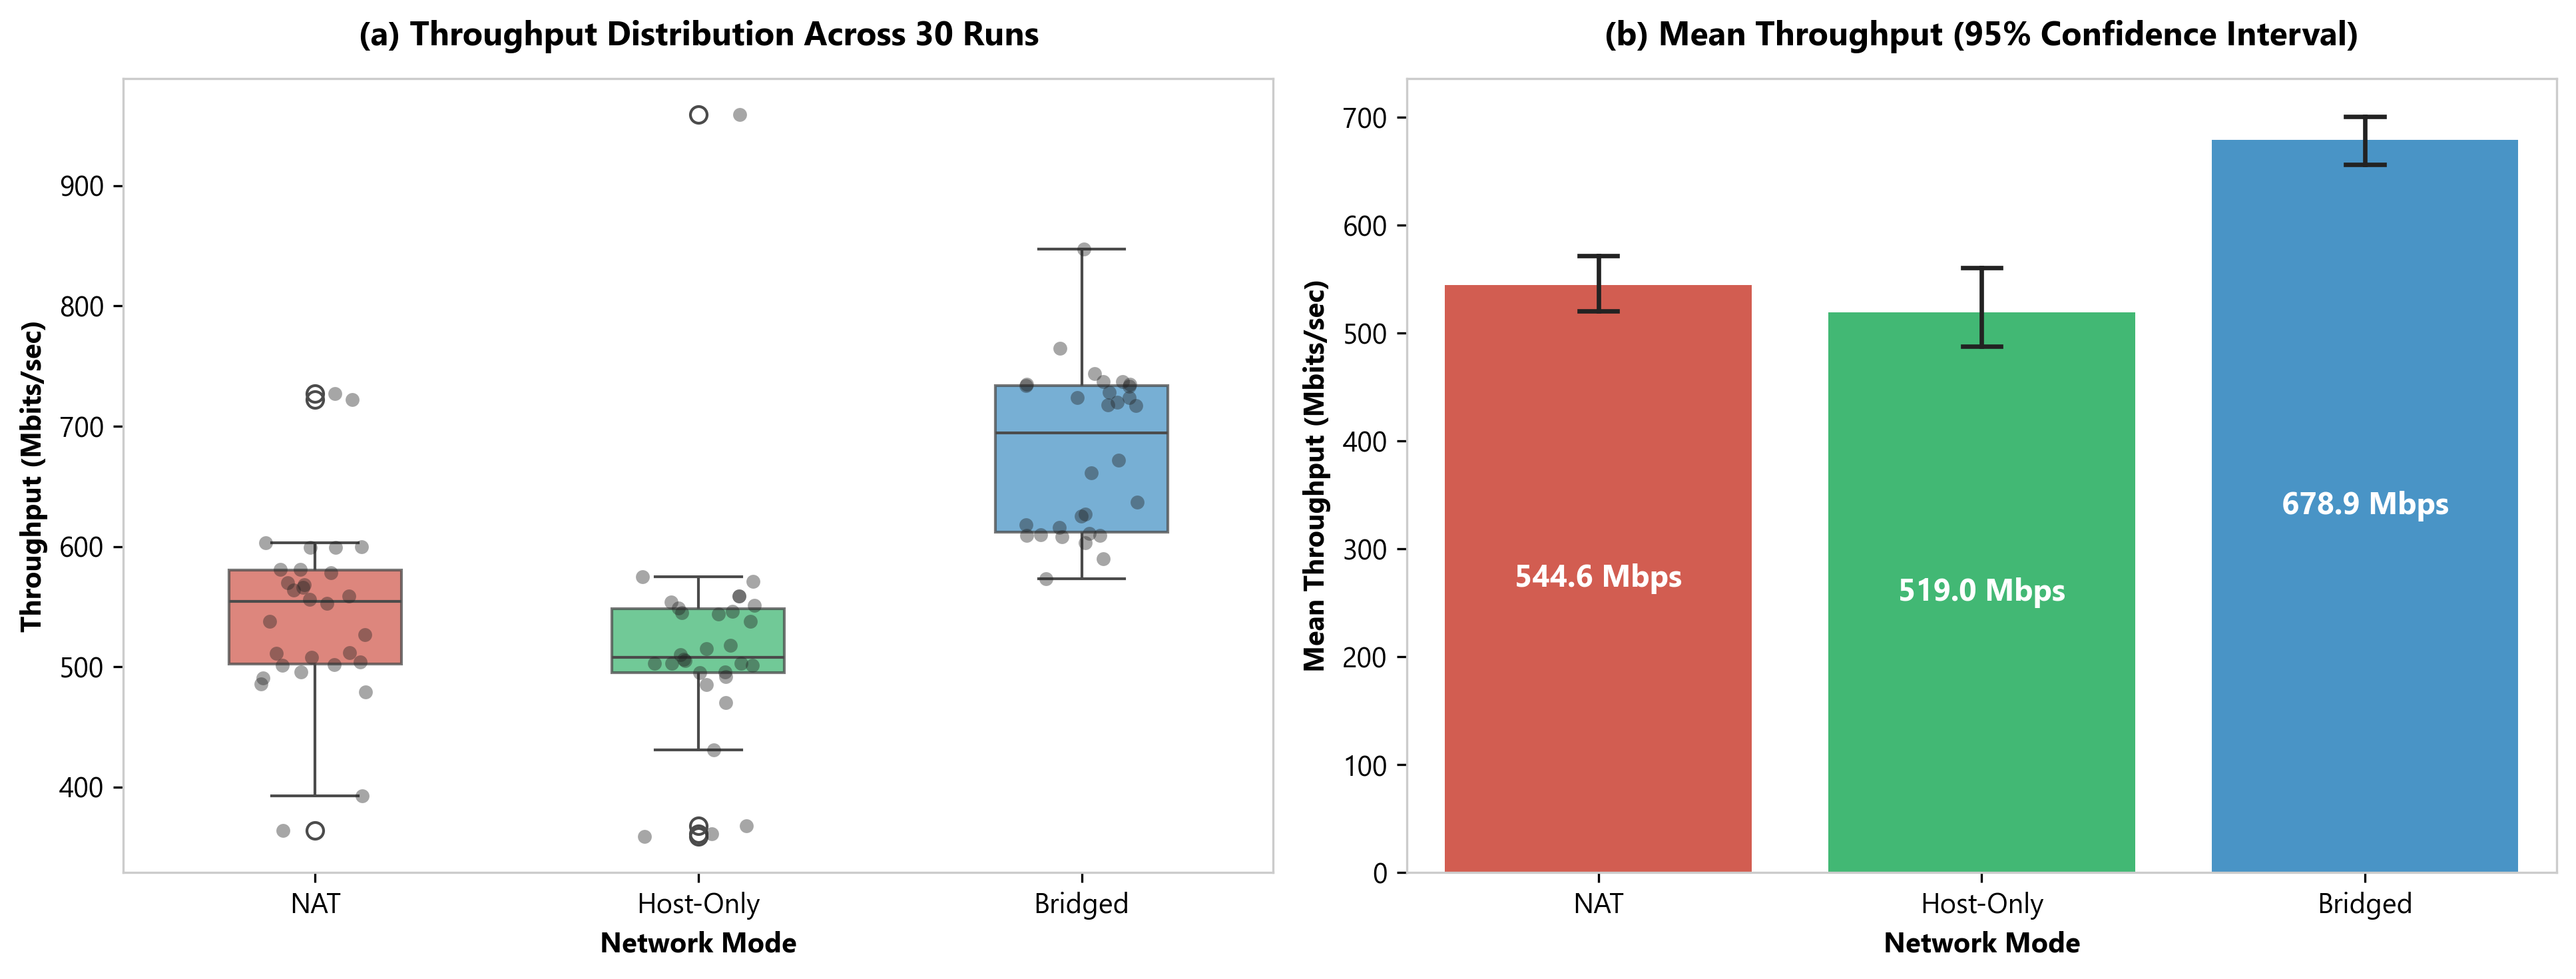

saved figure: figures\throughput_comparison.png


In [6]:
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=CONFIG["figures"]["dpi"])
palette = [CONFIG["modes"][m]["color"] for m in CONFIG["modes"]]

sns.boxplot(ax=ax1, data=df, x="mode", y="throughput_mbps", hue="mode", palette=palette, legend=False, width=0.45, boxprops=dict(alpha=0.75))
sns.stripplot(ax=ax1, data=df, x="mode", y="throughput_mbps", color="#222222", alpha=0.4, size=5, jitter=0.15)
ax1.set_title("(a) Throughput Distribution Across 30 Runs", fontweight="bold", pad=12)
ax1.set_xlabel("Network Mode", fontweight="bold")
ax1.set_ylabel("Throughput (Mbits/sec)", fontweight="bold")

sns.barplot(ax=ax2, data=df, x="mode", y="throughput_mbps", hue="mode", palette=palette, legend=False, capsize=0.1, err_kws={'linewidth': 1.6, 'color': '#222222'})
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{h:.1f} Mbps", (p.get_x() + p.get_width() / 2., h / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax2.set_title("(b) Mean Throughput (95% Confidence Interval)", fontweight="bold", pad=12)
ax2.set_xlabel("Network Mode", fontweight="bold")
ax2.set_ylabel("Mean Throughput (Mbits/sec)", fontweight="bold")

fig.tight_layout()
fig_path = CONFIG["output_figures_dir"] / "throughput_comparison.png"
fig.savefig(fig_path)
plt.show()
print(f"saved figure: {fig_path}")

### Latency Comparison

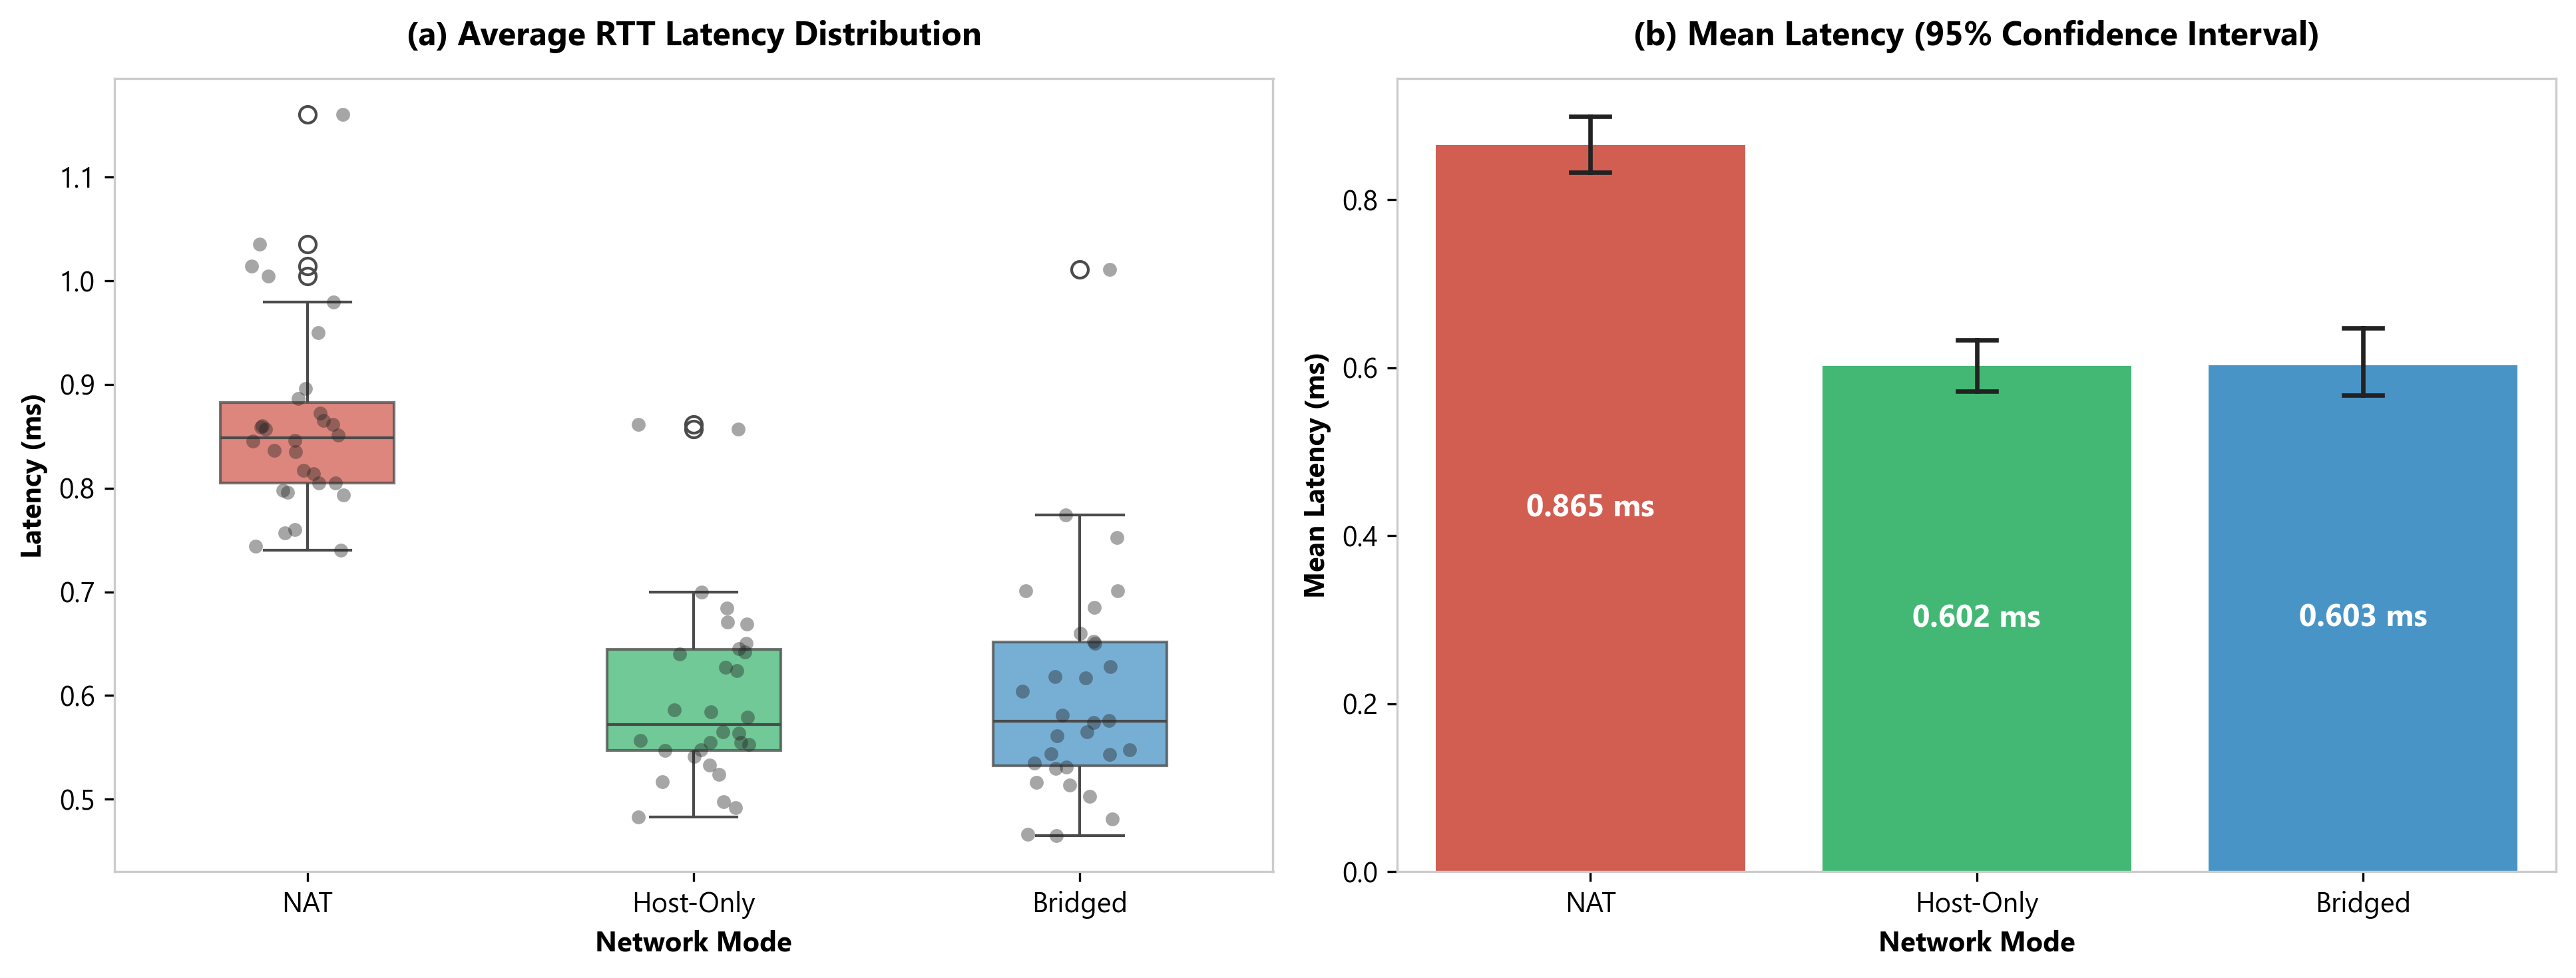

saved figure: figures\latency_comparison.png


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=CONFIG["figures"]["dpi"])

sns.boxplot(ax=ax1, data=df, x="mode", y="latency_avg_ms", hue="mode", palette=palette, legend=False, width=0.45, boxprops=dict(alpha=0.75))
sns.stripplot(ax=ax1, data=df, x="mode", y="latency_avg_ms", color="#222222", alpha=0.4, size=5, jitter=0.15)
ax1.set_title("(a) Average RTT Latency Distribution", fontweight="bold", pad=12)
ax1.set_xlabel("Network Mode", fontweight="bold")
ax1.set_ylabel("Latency (ms)", fontweight="bold")

sns.barplot(ax=ax2, data=df, x="mode", y="latency_avg_ms", hue="mode", palette=palette, legend=False, capsize=0.1, err_kws={'linewidth': 1.6, 'color': '#222222'})
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{h:.3f} ms", (p.get_x() + p.get_width() / 2., h / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax2.set_title("(b) Mean Latency (95% Confidence Interval)", fontweight="bold", pad=12)
ax2.set_xlabel("Network Mode", fontweight="bold")
ax2.set_ylabel("Mean Latency (ms)", fontweight="bold")

fig.tight_layout()
fig_path = CONFIG["output_figures_dir"] / "latency_comparison.png"
fig.savefig(fig_path)
plt.show()
print(f"saved figure: {fig_path}")

### Run-by-Run Temporal Stability (run 1-30)

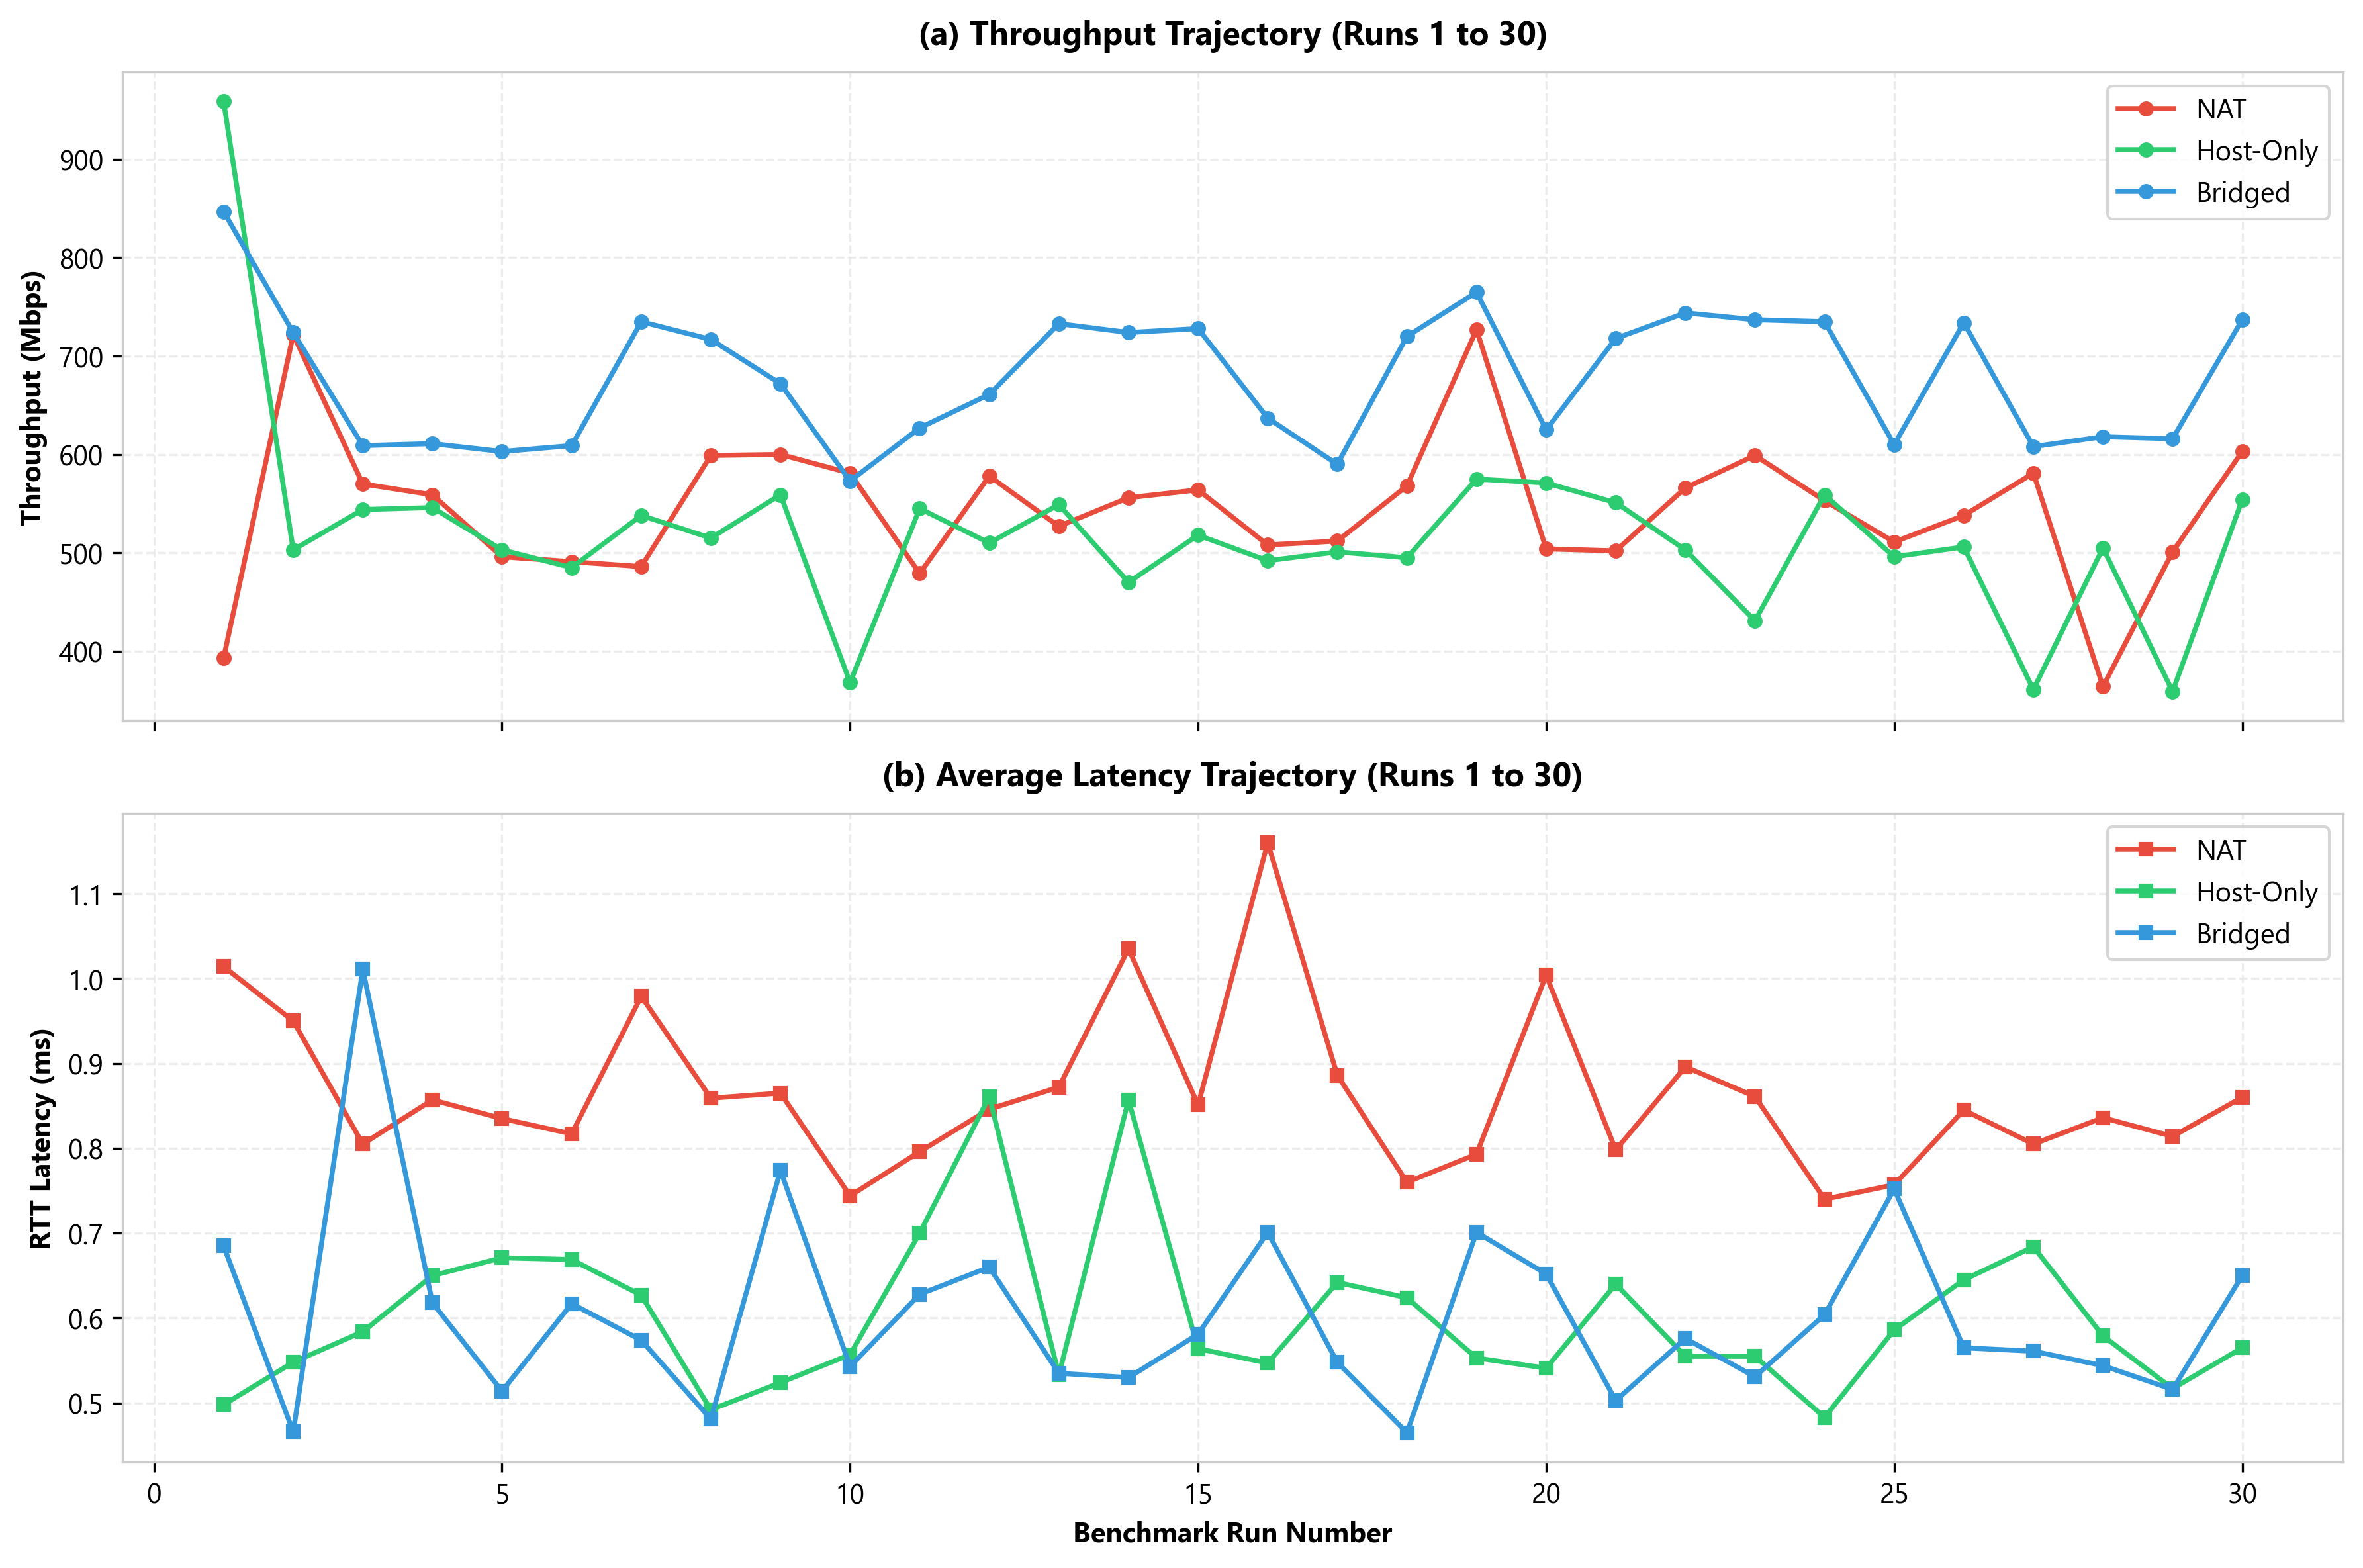

saved figure: figures\timeseries_stability.png


In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), dpi=CONFIG["figures"]["dpi"], sharex=True)

for mode, meta in CONFIG["modes"].items():
    subset = df[df["mode"] == mode]
    ax1.plot(subset["run"], subset["throughput_mbps"], marker="o", label=mode, color=meta["color"], linewidth=1.8, markersize=4.5)
    ax2.plot(subset["run"], subset["latency_avg_ms"], marker="s", label=mode, color=meta["color"], linewidth=1.8, markersize=4.5)

ax1.set_title("(a) Throughput Trajectory (Runs 1 to 30)", fontweight="bold", pad=10)
ax1.set_ylabel("Throughput (Mbps)", fontweight="bold")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True)

ax2.set_title("(b) Average Latency Trajectory (Runs 1 to 30)", fontweight="bold", pad=10)
ax2.set_xlabel("Benchmark Run Number", fontweight="bold")
ax2.set_ylabel("RTT Latency (ms)", fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True)

fig.tight_layout()
fig_path = CONFIG["output_figures_dir"] / "timeseries_stability.png"
fig.savefig(fig_path)
plt.show()
print(f"saved figure: {fig_path}")


In [9]:
# -----------------------------------------------------------------------------
# statistical tests

from itertools import combinations
from scipy import stats

metrics = {"throughput_mbps": "Throughput (Mbps)", "latency_avg_ms": "Latency (ms)"}
mode_names = list(CONFIG["modes"].keys())          # nat, host-only, bridged
pairs = list(combinations(mode_names, 2))          # all unique pairs
alpha = 0.05 / len(pairs)                          # bonferroni correction (0.05 / 3)

rows = []
for col, label in metrics.items():
    # omnibus test: do any of the modes differ overall?
    groups = [df[df["mode"] == m][col] for m in mode_names]
    _, p_all = stats.kruskal(*groups)
    print(f"{label}: kruskal-wallis p = {p_all:.3g}")

    # pairwise post-hoc: which specific pairs actually differ?
    for a, b in pairs:
        x = df[df["mode"] == a][col]
        y = df[df["mode"] == b][col]
        _, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        rows.append({
            "metric": label,
            "pair": f"{a} vs {b}",
            "mean_a": round(x.mean(), 3),
            "mean_b": round(y.mean(), 3),
            "diff_pct": round((y.mean() - x.mean()) / x.mean() * 100, 1),
            "p_value": float(f"{p:.3g}"),
            "significant": "yes" if p < alpha else "no",
        })

stat_table = pd.DataFrame(rows)
print(f"\nsignificance threshold (bonferroni): p < {alpha:.4f}\n")
print(stat_table.to_string(index=False))
stat_table.to_csv(CONFIG["output_results_dir"] / "statistical_tests.csv", index=False)

Throughput (Mbps): kruskal-wallis p = 6.9e-12
Latency (ms): kruskal-wallis p = 1.02e-11

significance threshold (bonferroni): p < 0.0167

           metric                 pair  mean_a  mean_b  diff_pct      p_value significant
Throughput (Mbps)     NAT vs Host-Only 544.600 519.033      -4.7 3.840000e-02          no
Throughput (Mbps)       NAT vs Bridged 544.600 678.900      24.7 3.330000e-09         yes
Throughput (Mbps) Host-Only vs Bridged 519.033 678.900      30.8 6.090000e-10         yes
     Latency (ms)     NAT vs Host-Only   0.865   0.602     -30.4 9.730000e-10         yes
     Latency (ms)       NAT vs Bridged   0.865   0.603     -30.3 7.370000e-10         yes
     Latency (ms) Host-Only vs Bridged   0.602   0.603       0.2 8.360000e-01          no


In [10]:
# export consolidated clean csv for external reporting
output_csv = CONFIG["output_results_dir"] / "benchmark_consolidated.csv"
df.to_csv(output_csv, index=False)
print(f"consolidated dataset exported to: {output_csv}")

consolidated dataset exported to: results\benchmark_consolidated.csv
